# Predicting Run vs. Pass from Pre-Snap NFL Data
**CS 363M Machine Learning, Fall 2026**

## §0 Introduction
We predict whether an NFL offense will run or pass using only information available before the snap: down, distance, field position, clock, score, weather, and how both teams lined up.

**Data:** 2022 nflverse play-by-play (situation, clock, score, weather) joined with participation data (formation, personnel, defenders in the box).

**Target:** `is_pass` = 1 for called passes (including sacks and scrambles), 0 for designed runs. Scrimmage plays only.

**Contents:** 1 Data · 2 Cleaning · 3 EDA · 4 Features · 5 Split and CV · 6 Modeling · 7 Results

In [1]:
import re
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
RANDOM_STATE = 363

## §1 Data acquisition and merge
### 1.1 Download
Both parquet files come from nflverse and are cached in `data/`.

In [2]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
BASE_URL = "https://github.com/nflverse/nflverse-data/releases/download"
FILES = {
    "pbp":  ("pbp", "play_by_play_2022.parquet"),
    "part": ("pbp_participation", "pbp_participation_2022.parquet"),
}

def fetch(release: str, fname: str) -> Path:
    """Download a file from an nflverse-data release unless it is already cached."""
    path = DATA_DIR / fname
    if not path.exists():
        print(f"Downloading {fname} ...")
        urllib.request.urlretrieve(f"{BASE_URL}/{release}/{fname}", path)
    return path

pbp  = pd.read_parquet(fetch(*FILES["pbp"]))
part = pd.read_parquet(fetch(*FILES["part"]))
print(f"pbp:           {pbp.shape[0]:>6,} rows x {pbp.shape[1]} cols")
print(f"participation: {part.shape[0]:>6,} rows x {part.shape[1]} cols")

pbp:           49,434 rows x 372 cols
participation: 50,150 rows x 20 cols


In [3]:
part.head(3)

,nflverse_game_id,old_game_id,play_id,possession_team,offense_formation,offense_personnel,defenders_in_box,defense_personnel,number_of_pass_rushers,players_on_play,offense_players,defense_players,n_offense,n_defense,ngs_air_yards,time_to_throw,was_pressure,route,defense_man_zone_type,defense_coverage_type
0,2022_01_BUF_LA,2022090800,1,,None,None,NaN,None,NaN,,,,0,0,NaN,NaN,None,None,None,None
1,2022_01_BUF_LA,2022090800,41,LA,None,None,NaN,None,NaN,52512;42818;48482;52835;48772;54696;48011;5284...,00-0036421;00-0035933;00-0035609;00-0035942;00...,00-0031787;00-0035352;00-0037318;00-0035308;00...,11,11,NaN,NaN,None,None,None,None
2,2022_01_BUF_LA,2022090800,56,BUF,SHOTGUN,"1 RB, 1 TE, 3 WR",6.0,"3 DL, 3 LB, 5 DB",4.0,42816;48512;43298;47844;43335;47879;44875;4791...,00-0035382;00-0035689;00-0033904;00-0027648;00...,00-0031785;00-0033072;00-0035663;00-0032889;00...,11,11,4.52,2.169,False,IN,ZONE_COVERAGE,COVER_6


### 1.2 Join keys
Align key names and types, and check for duplicate plays.

In [4]:
pbp["play_id"] = pbp["play_id"].astype("int64")
part["play_id"] = part["play_id"].astype("int64")
part = part.rename(columns={"nflverse_game_id": "game_id"})

KEYS = ["game_id", "play_id"]
assert not pbp.duplicated(KEYS).any(), "duplicate keys in pbp"
assert not part.duplicated(KEYS).any(), "duplicate keys in participation"
print("Games in pbp:", pbp.game_id.nunique(), "| games in participation:", part.game_id.nunique())
print("Season types in pbp:", pbp.season_type.value_counts().to_dict())

Games in pbp: 284 | games in participation: 284
Season types in pbp: {'REG': 47157, 'POST': 2277}


### 1.3 Join diagnostics
An outer join shows what each side would lose.

In [5]:
diag = pbp[KEYS].merge(part[KEYS + ["offense_formation", "n_offense"]],
                       on=KEYS, how="outer", indicator=True)
print(diag["_merge"].value_counts().rename({"left_only": "pbp only",
                                            "right_only": "participation only",
                                            "both": "matched"}))

part_only = diag[diag["_merge"] == "right_only"]
print(f"\nParticipation-only rows with a formation recorded: {part_only.offense_formation.notna().sum()}")
print(f"Participation-only rows with any offensive players:  {(part_only.n_offense > 0).sum()}")

_merge
matched               49434
participation only      716
pbp only                  0
Name: count, dtype: int64

Participation-only rows with a formation recorded: 0
Participation-only rows with any offensive players:  0


**Takeaway.** Every pbp play matches. The 716 unmatched participation rows are empty placeholders.

### 1.4 Inner join

In [6]:
df = pbp.merge(part.drop(columns=["old_game_id"]), on=KEYS, how="inner", validate="one_to_one")

assert len(df) == len(pbp), "inner join should keep every pbp play"
assert not df.duplicated(KEYS).any()
print(f"Merged: {df.shape[0]:,} rows x {df.shape[1]} cols")
df[["game_id", "play_id", "posteam", "down", "ydstogo", "play_type",
    "offense_formation", "offense_personnel", "defenders_in_box", "defense_personnel"]].head()

Merged: 49,434 rows x 389 cols


,game_id,play_id,posteam,down,ydstogo,play_type,offense_formation,offense_personnel,defenders_in_box,defense_personnel
0,2022_01_BAL_NYJ,1,None,NaN,0.0,None,None,None,NaN,None
1,2022_01_BAL_NYJ,43,NYJ,NaN,0.0,kickoff,None,None,NaN,None
2,2022_01_BAL_NYJ,68,NYJ,1.0,10.0,run,SINGLEBACK,"1 RB, 2 TE, 2 WR",7.0,"3 DL, 4 LB, 4 DB"
3,2022_01_BAL_NYJ,89,NYJ,1.0,10.0,pass,SHOTGUN,"1 RB, 2 TE, 2 WR",6.0,"3 DL, 4 LB, 4 DB"
4,2022_01_BAL_NYJ,115,NYJ,2.0,10.0,run,SINGLEBACK,"1 RB, 2 TE, 2 WR",7.0,"3 DL, 4 LB, 4 DB"


## §2 Cleaning

### 2.1 Scope
Keep plays with a `pass` or `rush` flag; drop 2-point tries, no-down plays and aborted snaps.

In [7]:
steps = [("merged", len(df))]

def log_step(name: str, frame: pd.DataFrame) -> pd.DataFrame:
    steps.append((name, len(frame)))
    return frame

print("play_type of rows with neither pass nor rush flag:")
print(df.loc[(df["pass"] != 1) & (df["rush"] != 1), "play_type"].value_counts(dropna=False).to_string())

clean = log_step("keep pass==1 or rush==1", df[(df["pass"] == 1) | (df["rush"] == 1)])
clean = log_step("drop 2-pt conversion tries", clean[clean["two_point_attempt"] != 1])
# 2-pt tries wiped out by a penalty are not flagged two_point_attempt, but they have no down
print("no-down plays left:", clean.loc[clean["down"].isna(), "desc"].str[:45].value_counts().to_dict())
clean = log_step("drop no-down plays (penalized 2-pt tries)", clean[clean["down"].notna()])
assert ((clean["pass"] + clean["rush"]) == 1).all(), 'pass and rush must be mutually exclusive'

play_type of rows with neither pass nor rush flag:
play_type
no_play        3123
kickoff        2835
punt           2294
None           1449
extra_point    1253
field_goal     1105
qb_kneel        442
qb_spike         63
no-down plays left: {'TWO-POINT CONVERSION ATTEMPT. 15-P.Mahomes pa': 2, 'TWO-POINT CONVERSION ATTEMPT. 3-R.Wilson pass': 2, 'TWO-POINT CONVERSION ATTEMPT. 4-D.Carr pass t': 1, 'TWO-POINT CONVERSION ATTEMPT. 16-J.Goff is sa': 1, 'TWO-POINT CONVERSION ATTEMPT. 10-J.Garoppolo ': 1, 'TWO-POINT CONVERSION ATTEMPT. 1-K.Murray pass': 1, 'TWO-POINT CONVERSION ATTEMPT. 12-T.Brady pass': 1, 'TWO-POINT CONVERSION ATTEMPT. 4-D.Ridder is s': 1, 'TWO-POINT CONVERSION ATTEMPT. 4-T.Heinicke pa': 1, 'TWO-POINT CONVERSION ATTEMPT. 17-J.Allen pass': 1, 'TWO-POINT CONVERSION ATTEMPT. 9-J.Burrow pass': 1}


In [8]:
# aborted (fumbled) snaps: nflverse labels almost all of them rush whatever was called, so drop them
aborted = clean[clean["aborted_play"] == 1]
print(f"{len(aborted)} aborted plays, labels: pass={int(aborted['pass'].sum())}, rush={int(aborted['rush'].sum())}")
print(aborted["desc"].head(3).str[:110].to_string())
clean = log_step("drop aborted snaps", clean[clean["aborted_play"] != 1])

113 aborted plays, labels: pass=1, rush=112
355    (7:36) (Shotgun) 6-B.Mayfield FUMBLES (Aborted...
463    (:39) (No Huddle, Shotgun) 6-B.Mayfield Aborte...
503    (1:27) 6-B.Mayfield FUMBLES (Aborted) at CLE 1...


In [9]:
# penalty-nullified plays and scrambles stay in: their flags still show the call
print(f"no_play rows kept: {(clean['play_type'] == 'no_play').sum():,}")
print(f"QB scrambles (play_type 'run', labelled pass): {((clean['play_type'] == 'run') & (clean['pass'] == 1)).sum():,}")

no_play rows kept: 1,423
QB scrambles (play_type 'run', labelled pass): 959


### 2.2 Target

In [10]:
clean = clean.copy()
clean["is_pass"] = clean["pass"].astype(int)

balance = clean["is_pass"].value_counts().rename({1: "pass", 0: "run"}).to_frame("plays")
balance["share"] = (balance["plays"] / len(clean)).round(3)
display(balance)
print(clean.groupby("season_type")["is_pass"].mean().round(3).rename("pass rate").to_string())
assert set(clean["is_pass"].unique()) == {0, 1}

,plays,share
is_pass,,
pass,22353,0.61
run,14263,0.39


season_type
POST    0.639
REG     0.609


**Takeaway:** 61% of plays are passes, so always guessing "pass" is already 61% accurate.

### 2.3 Leakage audit
We whitelist the columns known before the snap and drop the other ~350. `xpass` (nflverse's pass model) is kept only as a benchmark.

In [11]:
ID_COLS = ["game_id", "play_id", "week", "season_type", "posteam", "defteam",
           "home_team", "fixed_drive", "order_sequence"]
BENCHMARK_COLS = ["xpass"]    # never a feature: nflverse's own model, kept only as a benchmark
TARGET = "is_pass"

FEATURE_CANDIDATES = [
    # game situation (pbp)
    "down", "ydstogo", "yardline_100", "goal_to_go", "qtr",
    "quarter_seconds_remaining", "half_seconds_remaining", "game_seconds_remaining",
    "score_differential", "posteam_timeouts_remaining", "defteam_timeouts_remaining",
    "posteam_type", "wp", "spread_line", "total_line",
    # pre-snap alignment (pbp)
    "shotgun", "no_huddle",
    # personnel and formation (participation)
    "offense_formation", "offense_personnel", "defense_personnel", "defenders_in_box",
    # venue and weather (pbp)
    "roof", "surface", "temp", "wind", "weather",
]
KEEP = ID_COLS + BENCHMARK_COLS + FEATURE_CANDIDATES + [TARGET]
assert len(KEEP) == len(set(KEEP))
excluded = [c for c in clean.columns if c not in KEEP]
print(f"Keeping {len(KEEP)} of {clean.shape[1]} columns; excluding {len(excluded)}.")

Keeping 37 of 390 columns; excluding 353.


**Check:** univariate ROC-AUC of every numeric column, by value and by missingness (only the training weeks). The leakier the column, the closer it scores to 1.

In [12]:
from sklearn.metrics import roc_auc_score

def univariate_auc(frame: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
    rows = []
    for col in frame.select_dtypes(include="number").columns:
        x = frame[col]
        scores = {}
        ok = x.notna()
        if ok.sum() > 100 and x[ok].nunique() > 1 and y[ok].nunique() > 1:
            scores["value"] = roc_auc_score(y[ok], x[ok])
        if 0 < ok.mean() < 1:
            scores["missingness"] = roc_auc_score(y, ok.astype(int))
        if scores:
            kind, auc = max(scores.items(), key=lambda kv: abs(kv[1] - 0.5))
            rows.append((col, kind, max(auc, 1 - auc)))
    return pd.DataFrame(rows, columns=["column", "via", "auc"]).sort_values("auc", ascending=False)

TRAIN_MAX_WEEK = 14   # weeks 15-18 + playoffs are the held-out test set (§5)
scan_rows = clean["week"] <= TRAIN_MAX_WEEK
leak_scan = univariate_auc(clean[scan_rows].drop(columns=[TARGET]), clean.loc[scan_rows, TARGET])
leak_scan["status"] = np.where(leak_scan["column"].isin(FEATURE_CANDIDATES), "FEATURE", "excluded")
leak_scan.head(15)

,column,via,auc,status
181,pass,value,1.000000,excluded
182,rush,value,1.000000,excluded
194,pass_oe,value,1.000000,excluded
178,passer_jersey_number,missingness,0.999970,excluded
179,rusher_jersey_number,missingness,0.976147,excluded
16,qb_dropback,value,0.974169,excluded
196,number_of_pass_rushers,missingness,0.969519,excluded
119,rush_attempt,value,0.966758,excluded
140,rushing_yards,missingness,0.966561,excluded
120,pass_attempt,value,0.953674,excluded


In [13]:
top_features = leak_scan[leak_scan["status"] == "FEATURE"].head(8)
display(top_features)

LEAK_THRESHOLD = 0.90
suspicious = leak_scan[(leak_scan["auc"] > LEAK_THRESHOLD) & (leak_scan["status"] == "FEATURE")]
assert suspicious.empty, f"possible leakage in whitelisted features:\n{suspicious}"
for c in ["xpass", "pass_oe", "yards_gained", "air_yards", "qb_dropback", "number_of_pass_rushers"]:
    assert c not in FEATURE_CANDIDATES
print(f"No whitelisted feature exceeds univariate AUC {LEAK_THRESHOLD}.")
print(f"Benchmark xpass univariate AUC: {leak_scan.set_index('column').loc['xpass', 'auc']:.3f}")

,column,via,auc,status
195,defenders_in_box,value,0.710264,FEATURE
14,shotgun,value,0.692451,FEATURE
9,down,value,0.618672,FEATURE
60,wp,value,0.612571,FEATURE
29,score_differential,value,0.586759,FEATURE
4,half_seconds_remaining,value,0.552569,FEATURE
11,ydstogo,value,0.547672,FEATURE
3,quarter_seconds_remaining,value,0.547441,FEATURE


No whitelisted feature exceeds univariate AUC 0.9.
Benchmark xpass univariate AUC: 0.787


**Takeaway.** Every near-perfect column is post-snap and excluded; some leak only through missingness (e.g. `passer_jersey_number`). The best pre-snap features are `defenders_in_box` (0.71) and `shotgun` (0.69).

In [14]:
clean = clean[KEEP].reset_index(drop=True)
print(clean.shape)

(36616, 37)


### 2.4 Missing values

In [15]:
miss = clean[FEATURE_CANDIDATES].isna().sum()
miss = miss[miss > 0].to_frame("missing")
miss["pct"] = (100 * miss["missing"] / len(clean)).round(2)
display(miss)
print(pd.crosstab(clean["roof"], clean["temp"].isna().rename("temp missing")))
print("\nSample weather text:", clean["weather"].dropna().iloc[0])

,missing,pct
offense_formation,76,0.21
offense_personnel,1,0.00
defense_personnel,1,0.00
defenders_in_box,74,0.20
temp,22878,62.48
wind,22878,62.48
weather,1196,3.27


temp missing  False  True 
roof                      
closed            0   4262
dome              0   6865
open              0   1313
outdoors      13738  10438

Sample weather text: Rain and mid 70s Temp: 73° F, Humidity: 79%, Wind: W 3 mph


| Column(s) | Cause | Fix |
|---|---|---|
| formation, personnel, `defenders_in_box` | Tracking gap (< 0.3% of plays) | Drop rows |
| `temp`, `wind` in dome/closed games | No weather indoors | `is_indoor = 1`, 70°F, 0 mph |
| `temp`, `wind` in outdoor/open games | Not filled in by nflverse | Parse from the `weather` text |

In [16]:
# 1) NGS tracking gaps -> drop rows
ngs_cols = ["offense_formation", "offense_personnel", "defense_personnel", "defenders_in_box"]
clean = log_step("drop missing formation/personnel/box", clean.dropna(subset=ngs_cols))

# 2) indoor games: weather does not apply
clean["is_indoor"] = clean["roof"].isin(["dome", "closed"]).astype(int)
clean.loc[clean["is_indoor"] == 1, ["temp", "wind"]] = [70.0, 0.0]

# 3) outdoor games with missing numbers: parse the weather text
weather_txt = clean["weather"].fillna("")
parsed_temp = pd.to_numeric(weather_txt.str.extract(r"Temp:\s*(-?\d+)", expand=False))
parsed_wind = pd.to_numeric(weather_txt.str.extract(r"Wind:\s*[A-Za-z]*\s*(\d+)\s*mph", expand=False))
need_temp, need_wind = clean["temp"].isna(), clean["wind"].isna()
clean.loc[need_temp, "temp"] = parsed_temp[need_temp]
clean.loc[need_wind, "wind"] = parsed_wind[need_wind]
print(f"temp filled from weather text: {(need_temp & clean['temp'].notna()).sum():,}")
print(f"wind filled from weather text: {(need_wind & clean['wind'].notna()).sum():,}")

# 4) small text clean-ups
clean["surface"] = clean["surface"].replace("", "unknown")
clean["weather"] = clean["weather"].fillna("")   # parsed into rain/snow flags in §4

remaining = clean[FEATURE_CANDIDATES].isna().sum()
print(f"parsed ranges: temp {clean['temp'].min():.0f}-{clean['temp'].max():.0f} F, "
      f"wind {clean['wind'].min():.0f}-{clean['wind'].max():.0f} mph")
print("Still missing:", remaining[remaining > 0].to_dict() or "none")

temp filled from weather text: 11,721
wind filled from weather text: 11,721
parsed ranges: temp 6-92 F, wind 0-27 mph
Still missing: none


### 2.5 Categorical cardinality

In [17]:
form = clean["offense_formation"].value_counts().to_frame("plays")
form["share_%"] = (100 * form["plays"] / len(clean)).round(2)
display(form)

for col in ["offense_personnel", "defense_personnel"]:
    vc = clean[col].value_counts(normalize=True)
    print(f"{col}: {len(vc)} distinct strings; top 5 cover {vc.head(5).sum():.1%}, "
          f"{(vc < 0.005).sum()} groupings are under 0.5% of plays each")
print("\nexample odd strings:", clean.loc[clean["offense_personnel"].str.contains("DB|DL|LB|QB"),
                                         "offense_personnel"].unique()[:4])

,plays,share_%
offense_formation,,
SHOTGUN,20300,55.56
SINGLEBACK,8859,24.25
EMPTY,3003,8.22
I_FORM,2227,6.09
PISTOL,1578,4.32
JUMBO,312,0.85
WILDCAT,260,0.71


offense_personnel: 64 distinct strings; top 5 cover 94.8%, 56 groupings are under 0.5% of plays each
defense_personnel: 64 distinct strings; top 5 cover 82.8%, 51 groupings are under 0.5% of plays each

example odd strings: ['1 RB, 1 TE, 2 WR,1 LB' '2 QB, 1 RB, 1 TE, 2 WR' '2 QB, 1 RB, 2 TE, 1 WR'
 '2 QB, 1 RB, 0 TE, 3 WR']


**Takeaway.** All 7 formations are common enough to keep. Personnel has 64 groupings per side with a long tail, handled in the Feature Engineering section.

### 2.6 Cleaning summary

In [18]:
summary = pd.DataFrame(steps, columns=["step", "rows"])
summary["removed"] = -summary["rows"].diff().fillna(0).astype(int)
display(summary)

assert not clean.duplicated(["game_id", "play_id"]).any()
assert clean[TARGET].isin([0, 1]).all()
assert "yards_gained" not in FEATURE_CANDIDATES and "xpass" not in FEATURE_CANDIDATES
print(f"Clean table: {clean.shape[0]:,} plays x {clean.shape[1]} columns | pass rate {clean[TARGET].mean():.3f}")

,step,rows,removed
0,merged,49434,0
1,keep pass==1 or rush==1,36870,12564
2,drop 2-pt conversion tries,36742,128
3,drop no-down plays (penalized 2-pt tries),36729,13
4,drop aborted snaps,36616,113
5,drop missing formation/personnel/box,36539,77


Clean table: 36,539 plays x 38 columns | pass rate 0.610


## §3 Exploratory data analysis
Training weeks (1–14) only.

In [19]:
import matplotlib.pyplot as plt

RUN_COLOR, PASS_COLOR = "#2a78d6", "#eb6834"
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
NEUTRAL = "#8c8c8c"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})

YTG_BINS = [0, 2, 6, 10, 100]                      # yards to go: 1-2 | 3-6 | 7-10 | 11+
YTG_LABELS = ["1-2", "3-6", "7-10", "11+"]

eda = clean[clean["week"] <= TRAIN_MAX_WEEK].copy()
eda["ydstogo_bin"] = pd.cut(eda["ydstogo"], bins=YTG_BINS, labels=YTG_LABELS)
assert eda["ydstogo_bin"].notna().all()
overall_rate = eda["is_pass"].mean()
print(f"EDA rows (weeks 1-{TRAIN_MAX_WEEK}): {len(eda):,} | overall pass rate {overall_rate:.3f}")

EDA rows (weeks 1-14): 26,799 | overall pass rate 0.614


### 3.1 Class balance, down and distance

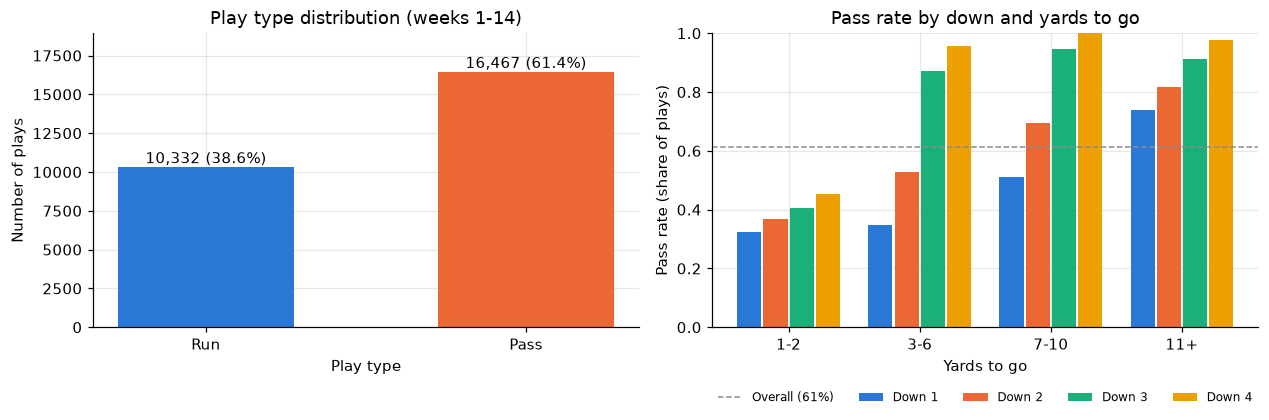

pass rate by down: {1: 0.51, 2: 0.63, 3: 0.8, 4: 0.68}


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = eda["is_pass"].map({0: "Run", 1: "Pass"}).value_counts().reindex(["Run", "Pass"])
axes[0].bar(counts.index, counts.values, color=[RUN_COLOR, PASS_COLOR], width=0.55)
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,} ({v / counts.sum():.1%})", ha="center", va="bottom")
axes[0].set(title="Play type distribution (weeks 1-14)", xlabel="Play type", ylabel="Number of plays",
            ylim=(0, counts.max() * 1.15))

rate = eda.pivot_table(index="ydstogo_bin", columns="down", values="is_pass", aggfunc="mean", observed=True)
width, x = 0.2, np.arange(len(rate.index))
for j, down in enumerate(rate.columns):
    axes[1].bar(x + (j - 1.5) * width, rate[down], width=width * 0.92, color=SERIES_COLORS[j], label=f"Down {int(down)}")
axes[1].axhline(overall_rate, color=NEUTRAL, ls="--", lw=1, label=f"Overall ({overall_rate:.0%})")
axes[1].set_xticks(x, rate.index)
axes[1].set(title="Pass rate by down and yards to go", xlabel="Yards to go", ylabel="Pass rate (share of plays)", ylim=(0, 1))
axes[1].legend(ncols=5, loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8, frameon=False)
plt.tight_layout()
plt.show()
print("pass rate by down:", eda.groupby(eda["down"].astype(int))["is_pass"].mean().round(2).to_dict())

**Takeaway.** Pass rate rises with down and distance: short yardage is 33–45% pass, while 3rd/4th down with 3+ yards to go is 87–100%. 1st-and-10 is close to 50/50.

### 3.2 Formation and personnel

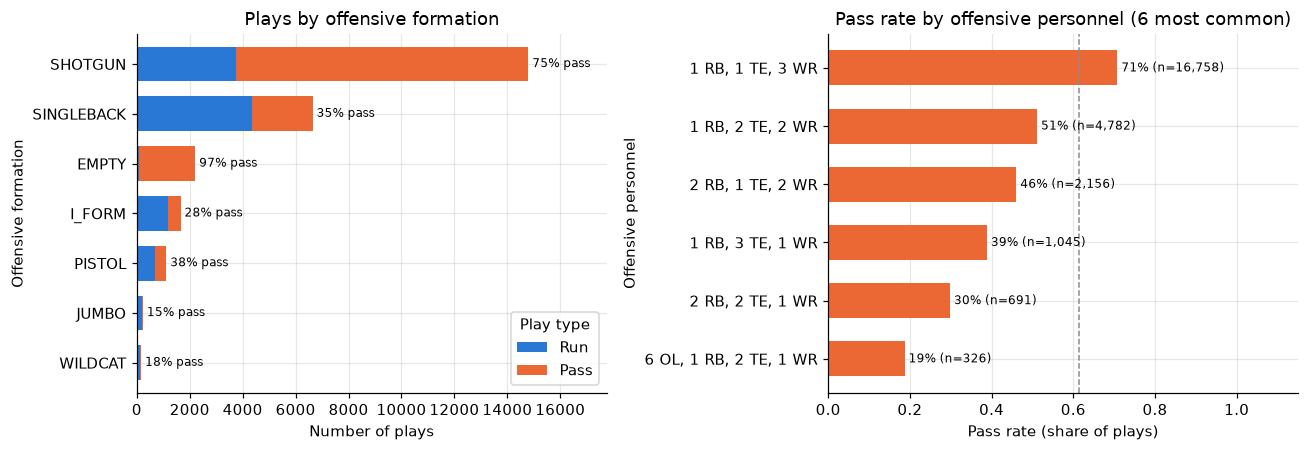

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

form = pd.crosstab(eda["offense_formation"], eda["is_pass"]).rename(columns={0: "Run", 1: "Pass"})
form = form.loc[form.sum(axis=1).sort_values().index]
form.plot.barh(stacked=True, ax=axes[0], color=[RUN_COLOR, PASS_COLOR], width=0.7)
for i, (_, row) in enumerate(form.iterrows()):
    axes[0].text(row.sum(), i, f" {row['Pass'] / row.sum():.0%} pass", va="center", fontsize=8)
axes[0].set(title="Plays by offensive formation", xlabel="Number of plays", ylabel="Offensive formation",
            xlim=(0, form.sum(axis=1).max() * 1.2))
axes[0].legend(title="Play type", loc="lower right")

top_pers = eda["offense_personnel"].value_counts().head(6).index
pers = (eda[eda["offense_personnel"].isin(top_pers)].groupby("offense_personnel")["is_pass"]
        .agg(["mean", "size"]).sort_values("mean"))
axes[1].barh(pers.index, pers["mean"], color=PASS_COLOR, height=0.6)
for i, (m, n) in enumerate(zip(pers["mean"], pers["size"])):
    axes[1].text(m, i, f" {m:.0%} (n={n:,})", va="center", fontsize=8)
axes[1].axvline(overall_rate, color=NEUTRAL, ls="--", lw=1)
axes[1].set(title="Pass rate by offensive personnel (6 most common)", xlabel="Pass rate (share of plays)",
            ylabel="Offensive personnel", xlim=(0, 1.15))
plt.tight_layout()
plt.show()

**Takeaway.** EMPTY is 97% pass and SHOTGUN 75%; I_FORM, JUMBO and WILDCAT are 15–28%. More WRs means more passing, extra linemen more running.

### 3.3 Score, quarter and clock

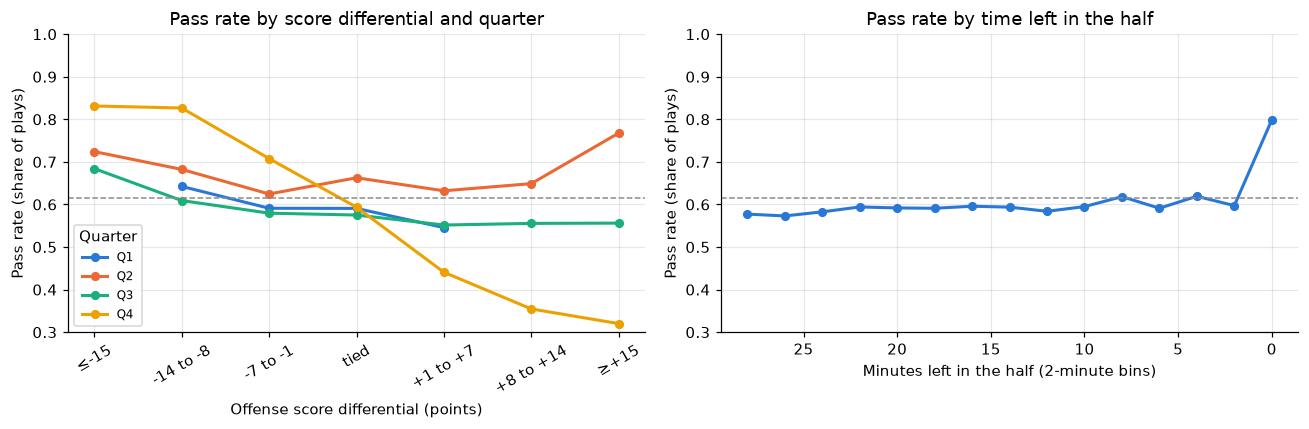

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

score_bins = [-100, -15, -8, -1, 0, 7, 14, 100]   # (a, b] intervals match the labels
score_labels = ["≤-15", "-14 to -8", "-7 to -1", "tied", "+1 to +7", "+8 to +14", "≥+15"]
reg = eda[eda["qtr"] <= 4].copy()
reg["score_bin"] = pd.cut(reg["score_differential"], bins=score_bins, labels=score_labels)
by_score = reg.pivot_table(index="score_bin", columns="qtr", values="is_pass", aggfunc="mean", observed=True)
n_score = reg.pivot_table(index="score_bin", columns="qtr", values="is_pass", aggfunc="size", observed=True)
by_score = by_score.where(n_score >= 50)   # hide rates based on fewer than 50 plays
for j, q in enumerate(by_score.columns):
    axes[0].plot(range(len(by_score)), by_score[q], marker="o", ms=5, lw=2, color=SERIES_COLORS[j], label=f"Q{int(q)}")
axes[0].set_xticks(range(len(by_score)), by_score.index, rotation=30)
axes[0].axhline(overall_rate, color=NEUTRAL, ls="--", lw=1)
axes[0].set(title="Pass rate by score differential and quarter", xlabel="Offense score differential (points)",
            ylabel="Pass rate (share of plays)", ylim=(0.3, 1))
axes[0].legend(title="Quarter", fontsize=8)

eda["min_left_half"] = pd.cut(eda["half_seconds_remaining"] / 60, bins=range(0, 32, 2), right=False)
by_clock = eda.groupby("min_left_half", observed=True)["is_pass"].mean()
axes[1].plot([iv.left for iv in by_clock.index], by_clock.values, marker="o", ms=5, lw=2, color=SERIES_COLORS[0])
axes[1].axhline(overall_rate, color=NEUTRAL, ls="--", lw=1)
axes[1].invert_xaxis()
axes[1].set(title="Pass rate by time left in the half", xlabel="Minutes left in the half (2-minute bins)",
            ylabel="Pass rate (share of plays)", ylim=(0.3, 1))
plt.tight_layout()
plt.show()

**Takeaway.** Score matters mainly in the 4th quarter (trailing by 8+: 83% pass; up 15+: 32%). Pass rate jumps to 80% in the last two minutes of a half.

### 3.4 Defenders in the box and weather

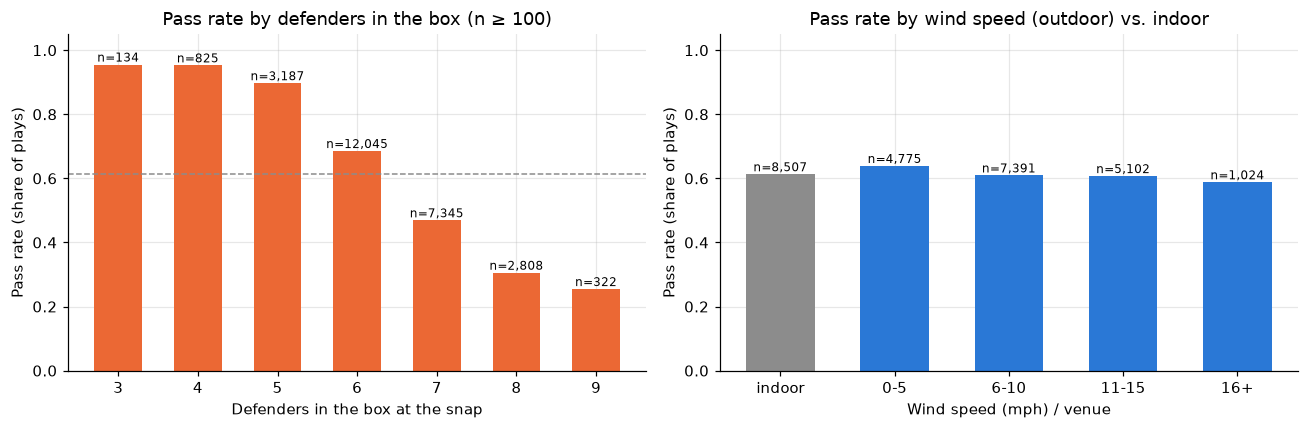

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

box = eda.groupby("defenders_in_box")["is_pass"].agg(["mean", "size"])
box = box[box["size"] >= 100]
axes[0].bar(box.index.astype(int).astype(str), box["mean"], color=PASS_COLOR, width=0.6)
for i, (m, n) in enumerate(zip(box["mean"], box["size"])):
    axes[0].text(i, m, f"n={n:,}", ha="center", va="bottom", fontsize=8)
axes[0].axhline(overall_rate, color=NEUTRAL, ls="--", lw=1)
axes[0].set(title="Pass rate by defenders in the box (n ≥ 100)", xlabel="Defenders in the box at the snap",
            ylabel="Pass rate (share of plays)", ylim=(0, 1.05))

venue = np.where(eda["is_indoor"] == 1, "indoor",
                 pd.cut(eda["wind"], bins=[-1, 5, 10, 15, 100], labels=["0-5", "6-10", "11-15", "16+"]).astype(str))
wind = eda.assign(venue=venue).groupby("venue")["is_pass"].agg(["mean", "size"]).reindex(["indoor", "0-5", "6-10", "11-15", "16+"])
axes[1].bar(wind.index, wind["mean"], color=[NEUTRAL] + [SERIES_COLORS[0]] * 4, width=0.6)
for i, (m, n) in enumerate(zip(wind["mean"], wind["size"])):
    axes[1].text(i, m, f"n={n:,}", ha="center", va="bottom", fontsize=8)
axes[1].set(title="Pass rate by wind speed (outdoor) vs. indoor", xlabel="Wind speed (mph) / venue",
            ylabel="Pass rate (share of plays)", ylim=(0, 1.05))
plt.tight_layout()
plt.show()

**Takeaway.** Box count is a strong signal (3–5 defenders: 90%+ pass; 8–9: 25–30%). Wind barely matters.

### 3.5 Feature correlations

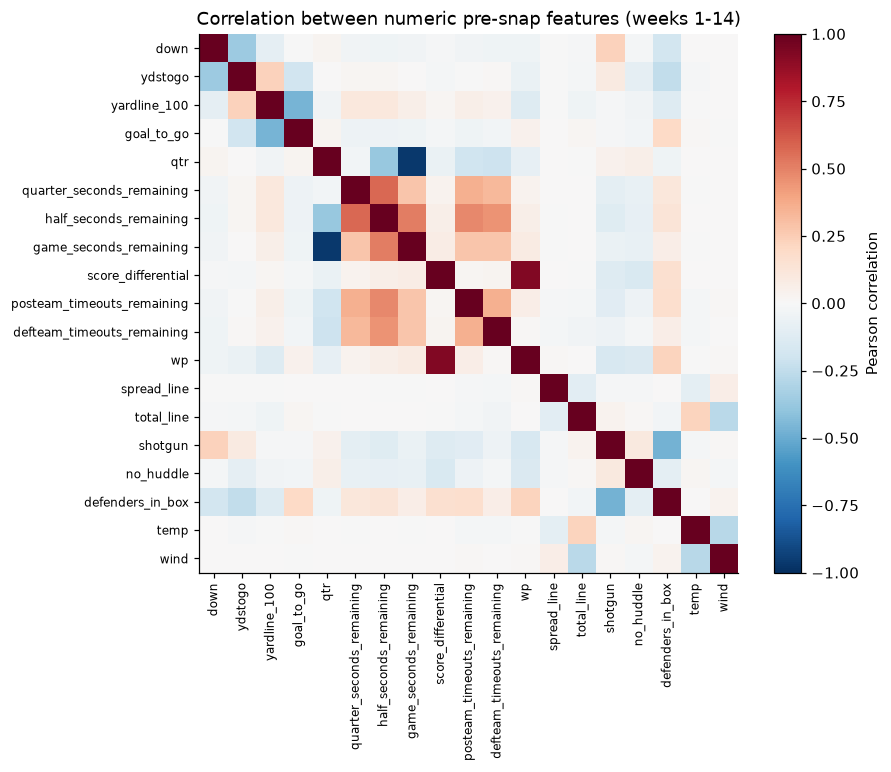

Most correlated feature pairs (|r| > 0.6):
qtr                 game_seconds_remaining   -0.96
score_differential  wp                        0.92


In [24]:
num_cols = [c for c in FEATURE_CANDIDATES if c in eda.select_dtypes("number").columns]
corr = eda[num_cols].corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(num_cols)), num_cols, fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation between numeric pre-snap features (weeks 1-14)")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Most correlated feature pairs (|r| > 0.6):")
print(pairs[pairs.abs() > 0.6].sort_values(key=abs, ascending=False).round(2).to_string())

**Takeaway.** Two near-redundant pairs: `qtr`/`game_seconds_remaining` (r = −0.96) and `score_differential`/`wp` (r = 0.92).

## §4 Feature engineering

| Group | Features |
|---|---|
| Personnel counts | `n_rb, n_te, n_wr, n_ol`, `n_dl, n_lb, n_db`, `box_minus_blockers` |
| Situation | `ydstogo_bin`, `red_zone`, `third_fourth_short`, `third_fourth_long`, `two_minute`, `trailing_late`, `posteam_spread`, `is_home` |
| Weather | `is_rain` |
| Sequence / tendency | `prev_play`, `drive_play_number`, `team_prior_pass_rate` |

In [25]:
data = clean.sort_values(["game_id", "order_sequence"]).reset_index(drop=True)   # true game order

### 4.1 Personnel counts
Parse strings like `"1 RB, 1 TE, 3 WR"` into counts (OL is only listed when there are more than 5).

In [26]:
POSITIONS = ["QB", "RB", "TE", "WR", "OL", "DL", "LB", "DB"]

def parse_personnel(text: str) -> dict:
    counts = dict.fromkeys(POSITIONS, 0)
    for number, pos in re.findall(r"(\d+)\s*(QB|RB|TE|WR|OL|DL|LB|DB)", text):
        counts[pos] += int(number)
    return counts

off = pd.DataFrame([parse_personnel(s) for s in data["offense_personnel"]], index=data.index)
dfn = pd.DataFrame([parse_personnel(s) for s in data["defense_personnel"]], index=data.index)

data["n_rb"], data["n_te"], data["n_wr"] = off["RB"], off["TE"], off["WR"]
data["n_ol"] = off["OL"].replace(0, 5)            # OL only listed when > 5
data["n_dl"], data["n_lb"], data["n_db"] = dfn["DL"], dfn["LB"], dfn["DB"]
# defenders in the box minus the offense's in-line blockers (OL + TE): a light box invites the run
data["box_minus_blockers"] = data["defenders_in_box"] - (data["n_ol"] + data["n_te"])

assert (off[["RB", "TE", "WR"]].sum(axis=1) > 0).all() and (dfn[["DL", "LB", "DB"]].sum(axis=1) > 0).all()
print("offense skill players (RB+TE+WR):", (off["RB"] + off["TE"] + off["WR"]).value_counts().to_dict())
print("defense players (DL+LB+DB):     ", (dfn["DL"] + dfn["LB"] + dfn["DB"]).value_counts().to_dict())
data[["offense_personnel", "n_rb", "n_te", "n_wr", "n_ol", "defense_personnel", "n_dl", "n_lb", "n_db",
      "defenders_in_box", "box_minus_blockers"]].drop_duplicates("offense_personnel").head(5)

offense skill players (RB+TE+WR): {5: 35249, 4: 1165, 6: 87, 3: 32, 2: 6}
defense players (DL+LB+DB):      {11: 36489, 10: 36, 12: 14}


,offense_personnel,n_rb,n_te,n_wr,n_ol,defense_personnel,n_dl,n_lb,n_db,defenders_in_box,box_minus_blockers
0,"1 RB, 2 TE, 2 WR",1,2,2,5,"3 DL, 4 LB, 4 DB",3,4,4,7.0,0.0
4,"2 RB, 1 TE, 2 WR",2,1,2,5,"4 DL, 3 LB, 4 DB",4,3,4,7.0,1.0
7,"2 RB, 2 TE, 1 WR",2,2,1,5,"4 DL, 3 LB, 4 DB",4,3,4,7.0,0.0
8,"0 RB, 2 TE, 3 WR",0,2,3,5,"3 DL, 3 LB, 5 DB",3,3,5,5.0,-2.0
11,"1 RB, 1 TE, 3 WR",1,1,3,5,"2 DL, 3 LB, 6 DB",2,3,6,6.0,0.0


### 4.2 Situation flags and offense-relative spread
`posteam_spread` flips the home-team point spread to the offense's view.

In [27]:
data["ydstogo_bin"] = pd.cut(data["ydstogo"], bins=YTG_BINS, labels=YTG_LABELS).astype(str)
data["red_zone"] = (data["yardline_100"] <= 20).astype(int)
data["third_fourth_short"] = ((data["down"] >= 3) & (data["ydstogo"] <= 2)).astype(int)
data["third_fourth_long"] = ((data["down"] >= 3) & (data["ydstogo"] >= 7)).astype(int)
data["two_minute"] = (data["half_seconds_remaining"] <= 120).astype(int)
data["trailing_late"] = ((data["score_differential"] < 0) & (data["game_seconds_remaining"] <= 900)).astype(int)

data["is_home"] = (data["posteam_type"] == "home").astype(int)
data["posteam_spread"] = np.where(data["is_home"] == 1, data["spread_line"], -data["spread_line"])

# sign check: favored offenses should tend to be ahead, so posteam_spread should correlate positively with the score
r_new = np.corrcoef(data["posteam_spread"], data["score_differential"])[0, 1]
r_raw = np.corrcoef(data["spread_line"], data["score_differential"])[0, 1]
print(f"corr with offense score differential: posteam_spread {r_new:.2f} | raw home-team spread_line {r_raw:.2f}")
assert r_new > 0.2, "posteam_spread has the wrong sign"

print(data[["red_zone", "third_fourth_short", "third_fourth_long", "two_minute", "trailing_late"]].mean().round(3).to_string())

corr with offense score differential: posteam_spread 0.31 | raw home-team spread_line 0.00
red_zone              0.147
third_fourth_short    0.056
third_fourth_long     0.099
two_minute            0.119
trailing_late         0.153


### 4.3 Weather flag
Rain from the weather text, outdoor games only.

In [28]:
weather_lc = data["weather"].str.lower()
data["is_rain"] = ((data["is_indoor"] == 0) & weather_lc.str.contains("rain|shower")).astype(int)
print(f"rain plays: {data['is_rain'].sum():,} in {data.loc[data['is_rain'] == 1, 'game_id'].nunique()} games")

rain plays: 2,201 in 17 games


### 4.4 Sequence and team-tendency features
Previous play in the drive, play number in the drive, and the offense's pass rate in earlier weeks.

In [29]:
drive = data.groupby(["game_id", "fixed_drive"])
data["drive_play_number"] = drive.cumcount() + 1
data["prev_play"] = drive["is_pass"].shift(1).map({1: "pass", 0: "run"}).fillna("none")
assert ((data["drive_play_number"] == 1) == (data["prev_play"] == "none")).all()

assert data.groupby(["posteam", "week"])["game_id"].nunique().max() == 1, "a team plays at most one game per week"

def team_prior_pass_rate(frame: pd.DataFrame) -> np.ndarray:
    """Each play's offense pass rate over earlier weeks of `frame` only (NaN if no earlier week)."""
    team_week = (frame.groupby(["posteam", "week"])["is_pass"].agg(passes="sum", plays="count")
                 .reset_index().sort_values(["posteam", "week"]))
    by_team = team_week.groupby("posteam")
    # cumulative totals minus the current week = totals over earlier weeks only
    team_week["rate"] = ((by_team["passes"].cumsum() - team_week["passes"])
                         / (by_team["plays"].cumsum() - team_week["plays"]))
    return frame[["posteam", "week"]].merge(team_week, on=["posteam", "week"], how="left")["rate"].to_numpy()

data["team_prior_pass_rate"] = team_prior_pass_rate(data)

# spot-check the chronology on one team-week against a direct computation
chk = data[(data["posteam"] == "KC") & (data["week"] == 10)]["team_prior_pass_rate"].iloc[0]
direct = data[(data["posteam"] == "KC") & (data["week"] < 10)]["is_pass"].mean()
assert np.isclose(chk, direct), (chk, direct)
assert data.loc[data["week"] == 1, "team_prior_pass_rate"].isna().all()
print(f"KC week 10 prior pass rate {chk:.3f} == direct mean over weeks 1-9 {direct:.3f}")
print("prev_play counts:", data["prev_play"].value_counts().to_dict())

KC week 10 prior pass rate 0.707 == direct mean over weeks 1-9 0.707
prev_play counts: {'pass': 17501, 'run': 13062, 'none': 5976}


### 4.5 Feature sets
**A** situation only → **B** + formation, personnel and box count → **C** + engineered features (main set).

In [30]:
SITUATION_NUM = ["down", "ydstogo", "yardline_100", "goal_to_go", "qtr", "quarter_seconds_remaining",
                 "half_seconds_remaining", "game_seconds_remaining", "score_differential",
                 "posteam_timeouts_remaining", "defteam_timeouts_remaining", "is_home", "total_line",
                 "temp", "wind", "is_indoor"]
ALIGN_NUM = ["shotgun", "no_huddle", "defenders_in_box"]
ALIGN_CAT = ["offense_formation", "offense_personnel", "defense_personnel"]
ENGINEERED_NUM = ["n_rb", "n_te", "n_wr", "n_ol", "n_dl", "n_lb", "n_db", "box_minus_blockers",
                  "red_zone", "third_fourth_short", "third_fourth_long", "two_minute", "trailing_late",
                  "posteam_spread", "is_rain", "drive_play_number", "team_prior_pass_rate"]
ENGINEERED_CAT = ["ydstogo_bin", "prev_play"]

FEATURE_SETS = {
    "A: game situation":        (SITUATION_NUM, []),
    "B: + formation/personnel": (SITUATION_NUM + ALIGN_NUM, ALIGN_CAT),
    "C: + engineered (final)":  (SITUATION_NUM + ALIGN_NUM + ENGINEERED_NUM, ALIGN_CAT + ENGINEERED_CAT),
}
NUM_FEATURES, CAT_FEATURES = FEATURE_SETS["C: + engineered (final)"]
FEATURES = NUM_FEATURES + CAT_FEATURES

# leakage guards: no IDs, benchmark or target; every input is a whitelisted column or built from them
FORBIDDEN = set(ID_COLS + BENCHMARK_COLS + [TARGET, "yards_gained", "pass", "rush", "play_type"])
assert FORBIDDEN.isdisjoint(FEATURES)
assert set(FEATURES) <= set(FEATURE_CANDIDATES) | set(ENGINEERED_NUM + ENGINEERED_CAT + ["is_home", "is_indoor"])
assert len(FEATURES) == len(set(FEATURES))
assert data[NUM_FEATURES].drop(columns="team_prior_pass_rate").notna().all().all()
print(f"{len(NUM_FEATURES)} numeric + {len(CAT_FEATURES)} categorical = {len(FEATURES)} input columns (set C)")

36 numeric + 5 categorical = 41 input columns (set C)


## §5 Train/test split and cross-validation
Train on weeks 1–14; test on weeks 15–18 + playoffs. CV uses 4 forward-chaining folds: each validates on two weeks and trains on all earlier weeks.

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, GroupKFold, RandomizedSearchCV, cross_validate,
                                     validation_curve)   # GroupKFold only for the comparison check below
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

train = data[data["week"] <= TRAIN_MAX_WEEK].reset_index(drop=True)
test = data[data["week"] > TRAIN_MAX_WEEK].reset_index(drop=True)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

assert set(train["game_id"]).isdisjoint(test["game_id"]), "a game appears in both train and test"
assert len(train) + len(test) == len(data)
assert not data.duplicated(["game_id", "play_id"]).any()
assert set(y_train.unique()) == {0, 1} and set(y_test.unique()) == {0, 1}

split = pd.DataFrame({
    "weeks": [f"1-{TRAIN_MAX_WEEK}", f"{TRAIN_MAX_WEEK + 1}-18 + playoffs"],
    "games": [train["game_id"].nunique(), test["game_id"].nunique()],
    "plays": [len(train), len(test)],
    "pass rate": [y_train.mean().round(3), y_test.mean().round(3)],
}, index=["train", "test"])
display(split)

VAL_BLOCKS = [(7, 8), (9, 10), (11, 12), (13, 14)]

def week_splits(weeks: pd.Series) -> list:
    """Forward-chaining CV: for each 2-week validation block, train on all earlier weeks."""
    w = weeks.to_numpy()
    return [(np.where(w < lo)[0], np.where((w >= lo) & (w <= hi))[0]) for lo, hi in VAL_BLOCKS]

cv = week_splits(train["week"])
fold_info = []
for (tr_idx, va_idx), (lo, hi) in zip(cv, VAL_BLOCKS):
    tr_rows, va_rows = train.iloc[tr_idx], train.iloc[va_idx]
    assert tr_rows["week"].max() < va_rows["week"].min()                # strictly chronological
    assert set(tr_rows["game_id"]).isdisjoint(va_rows["game_id"])      # whole games on one side
    # training features use training labels only: recomputing from training rows alone gives the same values
    assert np.allclose(team_prior_pass_rate(tr_rows), tr_rows["team_prior_pass_rate"], equal_nan=True)
    fold_info.append({"train weeks": f"1-{lo - 1}", "validation weeks": f"{lo}-{hi}",
                      "train plays": len(tr_idx), "validation plays": len(va_idx)})
display(pd.DataFrame(fold_info))

,weeks,games,plays,pass rate
train,1-14,208,26799,0.614
test,15-18 + playoffs,76,9740,0.599


,train weeks,validation weeks,train plays,validation plays
0,1-6,7-8,12130,3693
1,1-8,9-10,15823,3495
2,1-10,11-12,19318,3848
3,1-12,13-14,23166,3633


In [32]:
# for comparison: how often would GroupKFold let team_prior_pass_rate see validation-fold games?
leaky, total = 0, 0
for tr_idx, va_idx in GroupKFold(n_splits=5).split(X_train, y_train, train["game_id"]):
    val_weeks = train.iloc[va_idx].groupby("posteam")["week"].min()     # earliest validation game per team
    tr_rows = train.iloc[tr_idx]
    leaky += (tr_rows["week"] > tr_rows["posteam"].map(val_weeks)).sum()
    total += len(tr_idx)
print(f"GroupKFold: {leaky / total:.1%} of training-fold plays carry validation-fold labels in team_prior_pass_rate")
print("Forward-chaining: 0% (asserted above)")

GroupKFold: 62.6% of training-fold plays carry validation-fold labels in team_prior_pass_rate
Forward-chaining: 0% (asserted above)


### 5.1 Preprocessing pipeline
Median imputer for numeric columns (plus a scaler for logistic regression) and one-hot encoding for categoricals, fitted on training folds only.

In [33]:
def make_pipeline(model, num_cols=NUM_FEATURES, cat_cols=CAT_FEATURES, scale=False):
    num_steps = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else [])
    prep = ColumnTransformer(
        [("num", Pipeline(num_steps), num_cols),
         ("cat", OneHotEncoder(min_frequency=0.005, handle_unknown="infrequent_if_exist", sparse_output=False), cat_cols)],
        verbose_feature_names_out=False)
    return Pipeline([("prep", prep), ("model", model)])

prep_check = make_pipeline(DummyClassifier())["prep"].fit(X_train)
print(f"{len(FEATURES)} input columns -> {len(prep_check.get_feature_names_out())} model columns after one-hot encoding")

41 input columns -> 72 model columns after one-hot encoding


### 5.2 Evaluation
Main metric: ROC-AUC, the area under the ROC curve (0.5 = guessing, 1.0 = perfect). We also report accuracy, precision, recall and F1, with pass as the positive class.

In [34]:
SCORING = {"roc_auc": "roc_auc", "accuracy": "accuracy", "f1": "f1"}

def cv_summary(pipe, X=X_train, y=y_train, splits=cv) -> dict:
    """Mean forward-chaining CV scores on the training weeks (plus training-fold AUC to gauge overfitting)."""
    res = cross_validate(pipe, X, y, cv=splits, scoring=SCORING, return_train_score=True, n_jobs=-1)
    return {"CV ROC-AUC": res["test_roc_auc"].mean(), "CV AUC std": res["test_roc_auc"].std(),
            "CV accuracy": res["test_accuracy"].mean(), "CV F1": res["test_f1"].mean(),
            "train-fold AUC": res["train_roc_auc"].mean()}

def search_summary(search) -> dict:
    """Same metrics for the best configuration of a fitted Grid/RandomizedSearchCV."""
    r, i = search.cv_results_, search.best_index_
    return {"CV ROC-AUC": r["mean_test_roc_auc"][i], "CV AUC std": r["std_test_roc_auc"][i],
            "CV accuracy": r["mean_test_accuracy"][i], "CV F1": r["mean_test_f1"][i],
            "train-fold AUC": r["mean_train_roc_auc"][i]}

def top_configs(search, n=5) -> pd.DataFrame:
    r = pd.DataFrame(search.cv_results_)
    cols = [c for c in r.columns if c.startswith("param_")] + ["mean_test_roc_auc", "mean_train_roc_auc", "mean_test_accuracy"]
    out = r.sort_values("rank_test_roc_auc")[cols].head(n)
    return out.rename(columns=lambda c: c.replace("param_model__", "")).round(4)

cv_table = {}

## §6 Modeling
### 6.1 Baselines
Always predict the majority class, and predict pass whenever the QB is in shotgun.

In [35]:
majority = make_pipeline(DummyClassifier(strategy="most_frequent"))
majority.fit(X_train, y_train)
majority_class = majority["model"].classes_[np.argmax(majority["model"].class_prior_)]
print(f"Training class distribution: {y_train.value_counts(normalize=True).rename({1: 'pass', 0: 'run'}).round(3).to_dict()}")
print(f"Majority class: {'pass' if majority_class == 1 else 'run'} ({majority_class})")

cv_table["Majority baseline"] = cv_summary(majority)
# the shotgun rule needs no fitting: score it on the same validation blocks
shot_auc = [roc_auc_score(y_train.iloc[va], X_train["shotgun"].iloc[va]) for _, va in cv]
shot_acc = [accuracy_score(y_train.iloc[va], X_train["shotgun"].iloc[va]) for _, va in cv]
shot_f1 = [f1_score(y_train.iloc[va], X_train["shotgun"].iloc[va]) for _, va in cv]
cv_table["Shotgun rule"] = {"CV ROC-AUC": np.mean(shot_auc), "CV AUC std": np.std(shot_auc),
                            "CV accuracy": np.mean(shot_acc), "CV F1": np.mean(shot_f1), "train-fold AUC": np.nan}
pd.DataFrame(cv_table).T.round(4)

Training class distribution: {'pass': 0.614, 'run': 0.386}
Majority class: pass (1)


,CV ROC-AUC,CV AUC std,CV accuracy,CV F1,train-fold AUC
Majority baseline,0.5000,0.0000,0.6066,0.7551,0.5
Shotgun rule,0.6876,0.0015,0.7182,0.7816,NaN


**Takeaway.** Majority baseline: 60.7% accuracy, AUC 0.50. Shotgun rule: 71.8%, AUC 0.69.

### 6.2 Logistic regression
Tune `C` and the penalty (L1 vs. L2).

In [36]:
cv_table["Logistic regression (default)"] = cv_summary(make_pipeline(LogisticRegression(max_iter=2000), scale=True))

lr_grid = {"model__C": [0.001, 0.01, 0.1, 1, 10], "model__l1_ratio": [0, 1]}   # 0 = L2 penalty, 1 = L1
lr_search = GridSearchCV(make_pipeline(LogisticRegression(solver="liblinear", max_iter=2000), scale=True), lr_grid,
                         scoring=SCORING, refit="roc_auc", cv=cv, n_jobs=-1, return_train_score=True)
lr_search.fit(X_train, y_train)
cv_table["Logistic regression (tuned)"] = search_summary(lr_search)
display(pd.DataFrame(cv_table).T.loc[["Logistic regression (default)", "Logistic regression (tuned)"]].round(4))
print("best params:", lr_search.best_params_)
top_configs(lr_search)

,CV ROC-AUC,CV AUC std,CV accuracy,CV F1,train-fold AUC
Logistic regression (default),0.8184,0.0059,0.7470,0.7947,0.8202
Logistic regression (tuned),0.8184,0.0059,0.7472,0.7948,0.8202


best params: {'model__C': 1, 'model__l1_ratio': 0}


,C,l1_ratio,mean_test_roc_auc,mean_train_roc_auc,mean_test_accuracy
6,1.0,0,0.8184,0.8202,0.7472
8,10.0,0,0.8183,0.8203,0.7466
9,10.0,1,0.8183,0.8203,0.7467
7,1.0,1,0.8183,0.8201,0.7468
4,0.1,0,0.8179,0.8199,0.7474


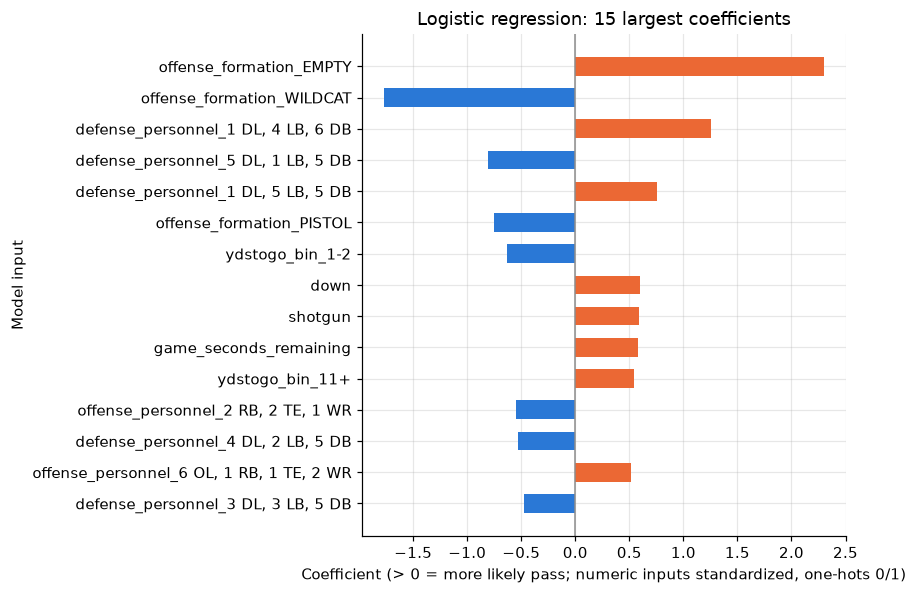

0 of 72 coefficients are exactly zero
most pass-leaning: {'offense_formation_EMPTY': 2.3, 'defense_personnel_1 DL, 4 LB, 6 DB': 1.26, 'defense_personnel_1 DL, 5 LB, 5 DB': 0.76, 'down': 0.6, 'shotgun': 0.58}
most run-leaning:  {'offense_formation_WILDCAT': -1.77, 'defense_personnel_5 DL, 1 LB, 5 DB': -0.81, 'offense_formation_PISTOL': -0.75, 'ydstogo_bin_1-2': -0.63, 'offense_personnel_2 RB, 2 TE, 1 WR': -0.55}


In [37]:
lr_best = lr_search.best_estimator_
coef = pd.Series(lr_best["model"].coef_[0], index=lr_best["prep"].get_feature_names_out())
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.values, color=[PASS_COLOR if v > 0 else RUN_COLOR for v in top.values], height=0.6)
ax.axvline(0, color=NEUTRAL, lw=1)
ax.set(title="Logistic regression: 15 largest coefficients", ylabel="Model input",
       xlabel="Coefficient (> 0 = more likely pass; numeric inputs standardized, one-hots 0/1)")
plt.tight_layout()
plt.show()
print(f"{(coef == 0).sum()} of {len(coef)} coefficients are exactly zero")
print("most pass-leaning:", coef.nlargest(5).round(2).to_dict())
print("most run-leaning: ", coef.nsmallest(5).round(2).to_dict())

**Takeaway.** CV AUC 0.818 with almost no overfitting; the default settings are already best. EMPTY formation, 6-DB defenses and shotgun push toward pass; WILDCAT, PISTOL and short yardage toward run.

### 6.3 Decision tree

In [38]:
cv_table["Decision tree (default)"] = cv_summary(make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)))
pd.DataFrame(cv_table).T.loc[["Decision tree (default)"]].round(4)

,CV ROC-AUC,CV AUC std,CV accuracy,CV F1,train-fold AUC
Decision tree (default),0.6465,0.0072,0.6611,0.7188,1.0


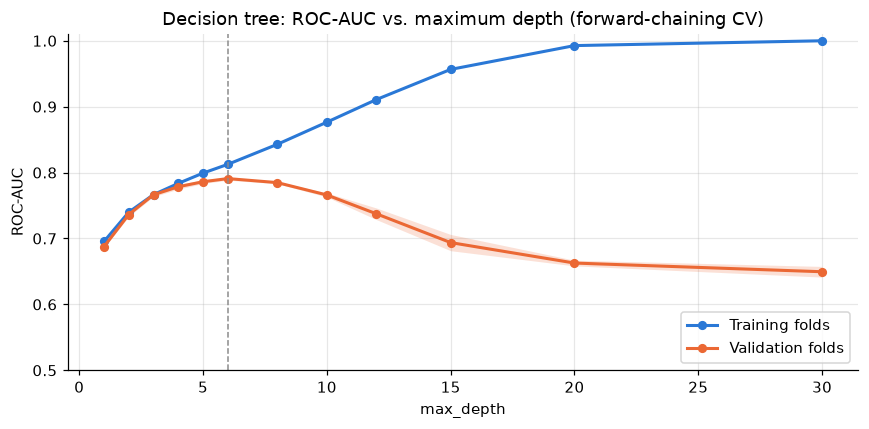

best validation AUC 0.7909 at max_depth=6


In [39]:
# depth vs. overfitting: training-fold vs. validation-fold AUC
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30]
train_auc, val_auc = validation_curve(
    make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)), X_train, y_train,
    param_name="model__max_depth", param_range=depths, cv=cv, scoring="roc_auc", n_jobs=-1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, train_auc.mean(axis=1), marker="o", ms=5, lw=2, color=SERIES_COLORS[0], label="Training folds")
ax.plot(depths, val_auc.mean(axis=1), marker="o", ms=5, lw=2, color=SERIES_COLORS[1], label="Validation folds")
ax.fill_between(depths, val_auc.mean(axis=1) - val_auc.std(axis=1), val_auc.mean(axis=1) + val_auc.std(axis=1),
                color=SERIES_COLORS[1], alpha=0.2, lw=0)
best_depth = depths[int(np.argmax(val_auc.mean(axis=1)))]
ax.axvline(best_depth, color=NEUTRAL, ls="--", lw=1)
ax.set(title="Decision tree: ROC-AUC vs. maximum depth (forward-chaining CV)", xlabel="max_depth",
       ylabel="ROC-AUC", ylim=(0.5, 1.01))
ax.legend()
plt.tight_layout()
plt.show()
print(f"best validation AUC {val_auc.mean(axis=1).max():.4f} at max_depth={best_depth}")

**Takeaway.** Validation AUC peaks at depth 6 while training AUC keeps climbing: classic overfitting. The default tree (0.65) is worse than the shotgun rule.

In [40]:
# grid search: depth x leaf size x split size x criterion (60 configs)
dt_grid = {
    "model__max_depth": [4, 6, 8, 10, 12],
    "model__min_samples_leaf": [1, 25, 100],
    "model__min_samples_split": [2, 200],
    "model__criterion": ["gini", "entropy"],
}
dt_search = GridSearchCV(make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)), dt_grid,
                         scoring=SCORING, refit="roc_auc", cv=cv, n_jobs=-1, return_train_score=True)
dt_search.fit(X_train, y_train)
cv_table["Decision tree (tuned)"] = search_summary(dt_search)
print("best params:", dt_search.best_params_)
top_configs(dt_search)

best params: {'model__criterion': 'entropy', 'model__max_depth': 12, 'model__min_samples_leaf': 100, 'model__min_samples_split': 2}


,criterion,max_depth,min_samples_leaf,min_samples_split,mean_test_roc_auc,mean_train_roc_auc,mean_test_accuracy
59,entropy,12,100,200,0.8116,0.8311,0.7402
58,entropy,12,100,2,0.8116,0.8311,0.7402
53,entropy,10,100,200,0.8107,0.8253,0.7405
52,entropy,10,100,2,0.8107,0.8253,0.7405
57,entropy,12,25,200,0.8089,0.8352,0.7383


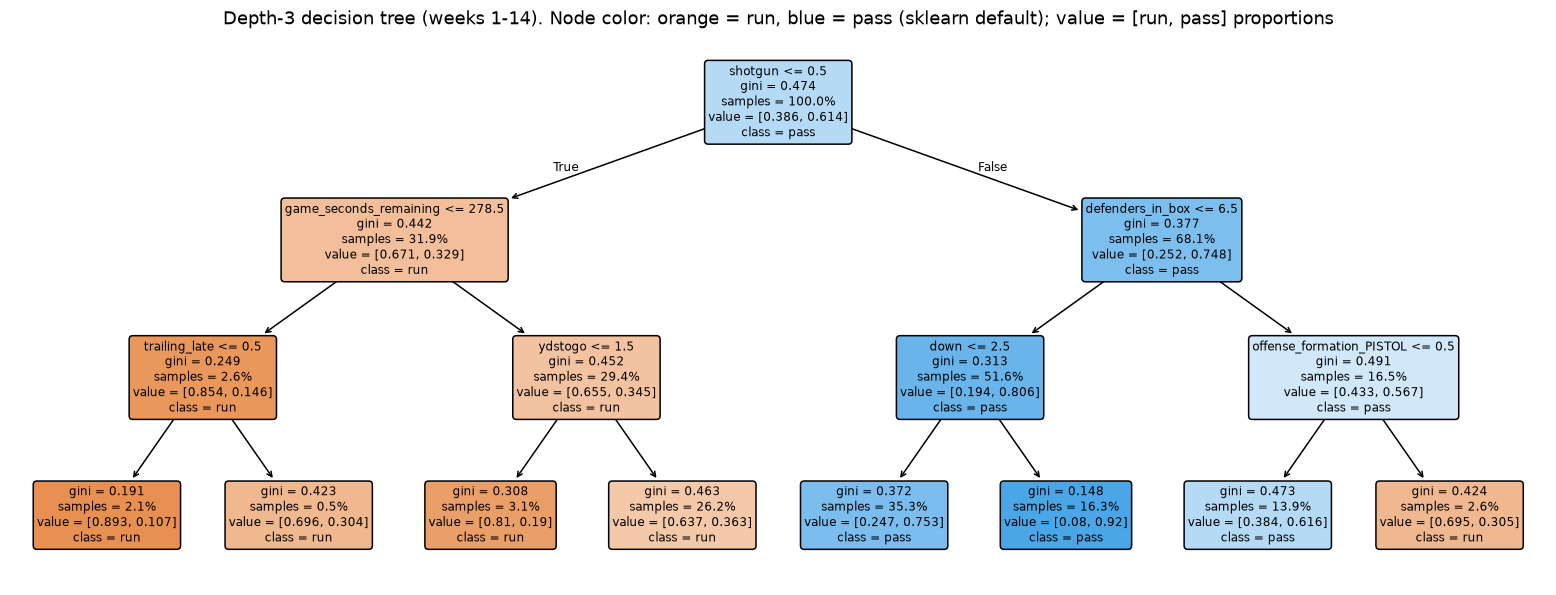

In [41]:
# a depth-3 tree for interpretation (the tuned tree is too deep to draw)
small_tree = make_pipeline(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(18, 6.5))
plot_tree(small_tree["model"], feature_names=small_tree["prep"].get_feature_names_out(), class_names=["run", "pass"],
          filled=True, impurity=True, proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Depth-3 decision tree (weeks 1-14). Node color: orange = run, blue = pass (sklearn default); value = [run, pass] proportions")
plt.show()

**Takeaway.** Tuning raises CV AUC from 0.651 to 0.812. The depth-3 tree splits on shotgun first, then box count, down and distance.

### 6.4 Random forest (bagging)

In [42]:
cv_table["Random forest (default)"] = cv_summary(make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)))
pd.DataFrame(cv_table).T.loc[["Random forest (default)"]].round(4)

,CV ROC-AUC,CV AUC std,CV accuracy,CV F1,train-fold AUC
Random forest (default),0.8202,0.0045,0.7459,0.7924,1.0


In [43]:
# randomized search: 12 of 192 combinations
rf_dist = {
    "model__n_estimators": [150, 300],
    "model__max_depth": [8, 12, 16, None],
    "model__min_samples_leaf": [1, 5, 20, 50],
    "model__max_features": ["sqrt", 0.25, 0.4],
    "model__class_weight": [None, "balanced"],
}
rf_search = RandomizedSearchCV(make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)), rf_dist, n_iter=12,
                               scoring=SCORING, refit="roc_auc", cv=cv, n_jobs=-1, return_train_score=True,
                               random_state=RANDOM_STATE)
rf_search.fit(X_train, y_train)
cv_table["Random forest (tuned)"] = search_summary(rf_search)
print("best params:", rf_search.best_params_)
top_configs(rf_search)

best params: {'model__n_estimators': 300, 'model__min_samples_leaf': 20, 'model__max_features': 0.4, 'model__max_depth': 16, 'model__class_weight': 'balanced'}


,n_estimators,min_samples_leaf,max_features,max_depth,class_weight,mean_test_roc_auc,mean_train_roc_auc,mean_test_accuracy
6,300,20,0.4,16,balanced,0.8265,0.8923,0.7377
0,150,5,0.4,12,None,0.8261,0.9157,0.7504
11,150,5,sqrt,16,balanced,0.8255,0.9257,0.7420
2,150,1,0.4,16,None,0.8245,0.9905,0.7500
3,300,50,0.4,None,balanced,0.8238,0.8583,0.7359


**Takeaway.** The default forest already reaches 0.820; tuning adds +0.006.

### 6.5 AdaBoost (boosting)

In [44]:
cv_table["AdaBoost (default)"] = cv_summary(make_pipeline(AdaBoostClassifier(random_state=RANDOM_STATE)))
pd.DataFrame(cv_table).T.loc[["AdaBoost (default)"]].round(4)

,CV ROC-AUC,CV AUC std,CV accuracy,CV F1,train-fold AUC
AdaBoost (default),0.8066,0.0039,0.7384,0.7911,0.8088


In [45]:
# grid search: base-tree depth x number of trees x learning rate (18 configs)
ada_grid = {
    "model__estimator__max_depth": [1, 2, 3],
    "model__n_estimators": [100, 300],
    "model__learning_rate": [0.1, 0.5, 1.0],
}
ada_search = GridSearchCV(
    make_pipeline(AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), random_state=RANDOM_STATE)),
    ada_grid, scoring=SCORING, refit="roc_auc", cv=cv, n_jobs=-1, return_train_score=True)
ada_search.fit(X_train, y_train)
cv_table["AdaBoost (tuned)"] = search_summary(ada_search)
print("best params:", ada_search.best_params_)
top_configs(ada_search)

best params: {'model__estimator__max_depth': 3, 'model__learning_rate': 0.5, 'model__n_estimators': 300}


,estimator__max_depth,learning_rate,n_estimators,mean_test_roc_auc,mean_train_roc_auc,mean_test_accuracy
15,3,0.5,300,0.8267,0.8383,0.7491
11,2,1.0,300,0.8250,0.8376,0.7497
14,3,0.5,100,0.8234,0.8316,0.7466
17,3,1.0,300,0.8234,0.8443,0.7468
9,2,0.5,300,0.8233,0.8299,0.7485


**Takeaway.** Tuning (depth-3 trees, 300 rounds, learning rate 0.5) raises CV AUC from 0.807 to 0.827.

### 6.6 Model comparison
The model with the highest CV ROC-AUC is selected.

In [46]:
cv_df = pd.DataFrame(cv_table).T
cv_df["AUC gain from tuning"] = np.nan
for name in ["Logistic regression", "Decision tree", "Random forest", "AdaBoost"]:
    cv_df.loc[f"{name} (tuned)", "AUC gain from tuning"] = (cv_df.loc[f"{name} (tuned)", "CV ROC-AUC"]
                                                           - cv_df.loc[f"{name} (default)", "CV ROC-AUC"])
display(cv_df.round(4))

searches = {"Logistic regression": lr_search, "Decision tree": dt_search, "Random forest": rf_search, "AdaBoost": ada_search}
best_name = max(searches, key=lambda n: searches[n].best_score_)
best_search = searches[best_name]
print(f"Selected model (highest CV ROC-AUC): {best_name}  ->  {best_search.best_score_:.4f}")

,CV ROC-AUC,CV AUC std,CV accuracy,CV F1,train-fold AUC,AUC gain from tuning
Majority baseline,0.5000,0.0000,0.6066,0.7551,0.5000,NaN
Shotgun rule,0.6876,0.0015,0.7182,0.7816,NaN,NaN
Logistic regression (default),0.8184,0.0059,0.7470,0.7947,0.8202,NaN
Logistic regression (tuned),0.8184,0.0059,0.7472,0.7948,0.8202,-0.0000
Decision tree (default),0.6465,0.0072,0.6611,0.7188,1.0000,NaN
Decision tree (tuned),0.8116,0.0058,0.7402,0.7891,0.8311,0.1651
Random forest (default),0.8202,0.0045,0.7459,0.7924,1.0000,NaN
Random forest (tuned),0.8265,0.0039,0.7377,0.7631,0.8923,0.0063
AdaBoost (default),0.8066,0.0039,0.7384,0.7911,0.8088,NaN
AdaBoost (tuned),0.8267,0.0040,0.7491,0.7976,0.8383,0.0200


Selected model (highest CV ROC-AUC): AdaBoost  ->  0.8267


**Takeaway.** All four models beat both baselines. AdaBoost (0.8267) is selected, essentially tied with the random forest (0.8265); logistic regression (0.818) beats the tuned tree (0.812).

### 6.7 Feature-set ablation
CV AUC on feature sets A → B → C.

In [47]:
from sklearn.base import clone

ablation_models = {"Logistic regression": (lr_search.best_estimator_["model"], True),
                   best_name: (best_search.best_estimator_["model"], False)}
ablation = {}
for set_name, (num, cat) in FEATURE_SETS.items():
    ablation[set_name] = {"n input columns": len(num) + len(cat)}
    for model_name, (model, scale) in ablation_models.items():
        pipe = make_pipeline(clone(model), num, cat, scale=scale)
        ablation[set_name][f"{model_name} CV AUC"] = cv_summary(pipe, X=train[num + cat])["CV ROC-AUC"]
ablation_df = pd.DataFrame(ablation).T
ablation_df.round(4)

,n input columns,Logistic regression CV AUC,AdaBoost CV AUC
A: game situation,16.0,0.7179,0.7710
B: + formation/personnel,22.0,0.8090,0.8214
C: + engineered (final),41.0,0.8184,0.8267


**Takeaway.** The participation data is the big gain (+0.05 to +0.09). Engineered features add a little, more for logistic regression (+0.009) than AdaBoost (+0.005).

## §7 Results
### 7.1 Test-set evaluation
Each tuned model is scored once on weeks 15–18 + playoffs.

In [48]:
final_models = {"Logistic regression": lr_search.best_estimator_, "Decision tree": dt_search.best_estimator_, "Random forest": rf_search.best_estimator_,
                "AdaBoost": ada_search.best_estimator_}

test_proba = {"Majority baseline": majority.predict_proba(X_test)[:, 1],
              "Shotgun rule": X_test["shotgun"].to_numpy(dtype=float)}
for name, model in final_models.items():
    test_proba[name] = model.predict_proba(X_test)[:, 1]
for name, p in test_proba.items():
    assert p.shape == (len(X_test),) and np.all((p >= 0) & (p <= 1)) and not np.isnan(p).any(), name

def test_metrics(y_true, proba, threshold=0.5) -> dict:
    pred = (proba >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_true, pred),
            "precision (pass)": precision_score(y_true, pred, zero_division=0),
            "recall (pass)": recall_score(y_true, pred),
            "F1 (pass)": f1_score(y_true, pred),
            "recall (run)": recall_score(y_true, pred, pos_label=0),
            "macro F1": f1_score(y_true, pred, average="macro"),
            "ROC-AUC": roc_auc_score(y_true, proba)}

results = pd.DataFrame({name: test_metrics(y_test, p) for name, p in test_proba.items()}).T
results["Δ accuracy vs. majority (pp)"] = 100 * (results["accuracy"] - results.loc["Majority baseline", "accuracy"])
cv_col = {"Majority baseline": "Majority baseline", "Shotgun rule": "Shotgun rule",
          "Logistic regression": "Logistic regression (tuned)", "Decision tree": "Decision tree (tuned)",
          "Random forest": "Random forest (tuned)", "AdaBoost": "AdaBoost (tuned)"}
results.insert(0, "CV ROC-AUC (train weeks)", [cv_df.loc[cv_col[n], "CV ROC-AUC"] for n in results.index])
results.round(4)

,CV ROC-AUC (train weeks),accuracy,precision (pass),recall (pass),F1 (pass),recall (run),macro F1,ROC-AUC,Δ accuracy vs. majority (pp)
Majority baseline,0.5000,0.5992,0.5992,1.0000,0.7494,0.0000,0.3747,0.5000,0.0000
Shotgun rule,0.6876,0.7123,0.7211,0.8477,0.7793,0.5100,0.6831,0.6788,11.3142
Logistic regression,0.8184,0.7431,0.7765,0.8021,0.7891,0.6550,0.7303,0.8179,14.3943
Decision tree,0.8116,0.7388,0.7746,0.7956,0.7850,0.6539,0.7262,0.8104,13.9630
Random forest,0.8265,0.7433,0.8494,0.6948,0.7644,0.8158,0.7413,0.8312,14.4148
AdaBoost,0.8267,0.7482,0.7806,0.8064,0.7933,0.6611,0.7356,0.8281,14.8973


**Takeaway.** Every model beats the majority baseline by 14–15 accuracy points. AdaBoost reaches 74.8% accuracy (AUC 0.828), and test AUCs are within 0.005 of CV.

### 7.2 Confusion matrices

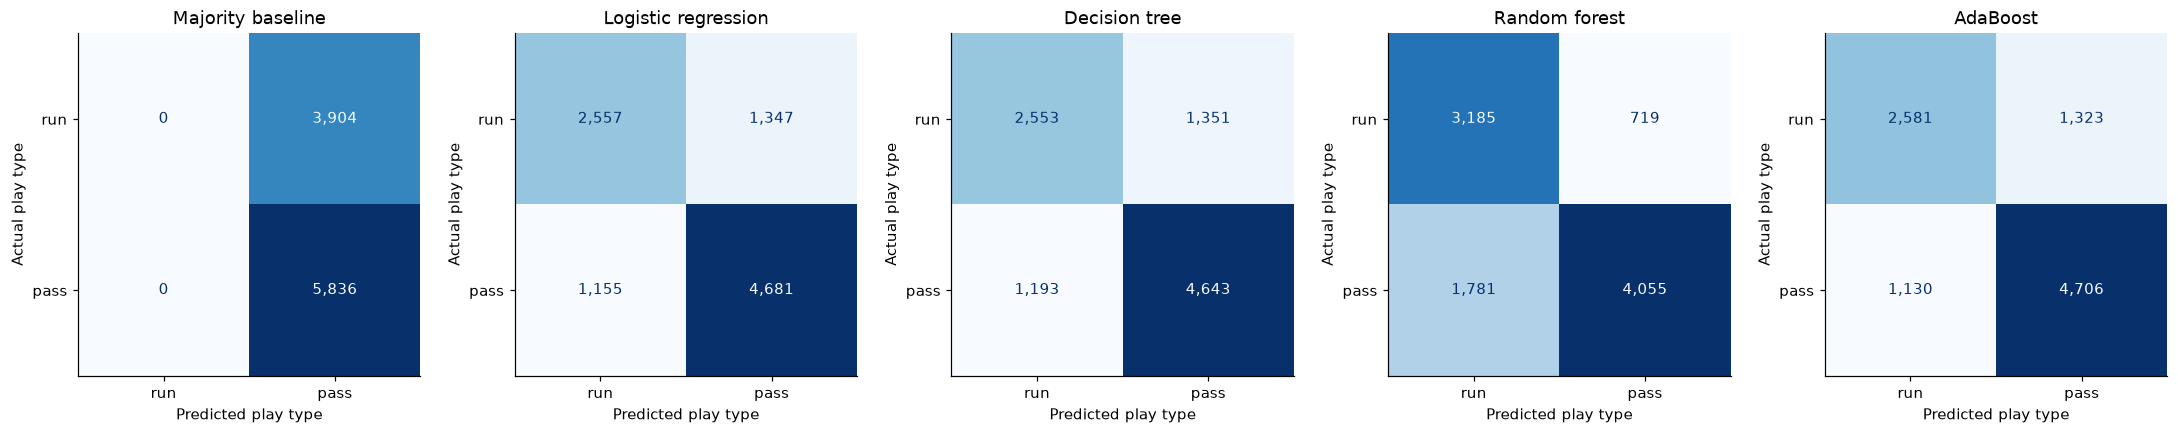

In [49]:
cm_models = ["Majority baseline", "Logistic regression", "Decision tree", "Random forest", "AdaBoost"]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, name in zip(axes, cm_models):
    pred = (test_proba[name] >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]), display_labels=["run", "pass"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set(title=name, xlabel="Predicted play type", ylabel="Actual play type")
    ax.grid(False)
plt.tight_layout()
plt.show()

**Takeaway.** Most models catch ~65% of runs and ~80% of passes; the class-weighted forest catches more runs (82%) but fewer passes (69%).

### 7.3 ROC curves and the `xpass` benchmark

,accuracy,precision (pass),recall (pass),F1 (pass),recall (run),macro F1,ROC-AUC
nflverse xpass (external benchmark),0.7080,0.7478,0.7736,0.7605,0.6099,0.6933,0.7884
AdaBoost (ours),0.7482,0.7806,0.8064,0.7933,0.6611,0.7356,0.8281


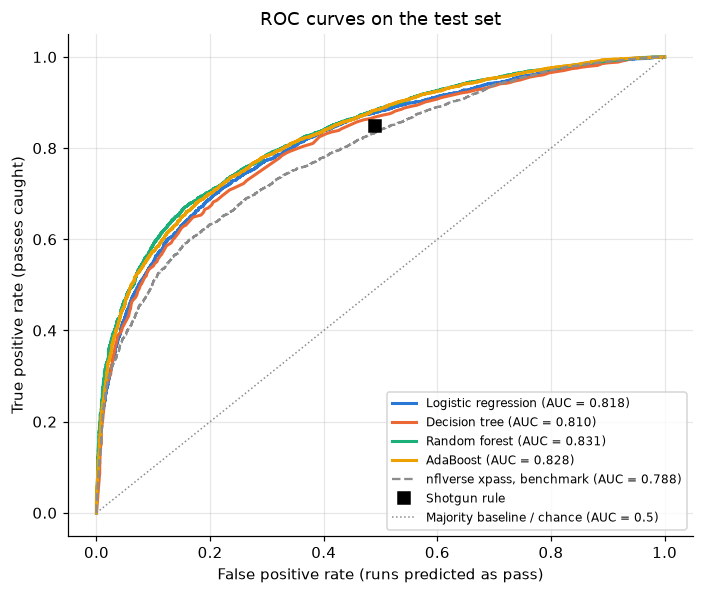

In [50]:
xpass_test = test["xpass"]
assert xpass_test.notna().all(), "xpass missing on some test plays"
xpass_row = test_metrics(y_test, xpass_test.to_numpy())
display(pd.DataFrame({"nflverse xpass (external benchmark)": xpass_row,
                      f"{best_name} (ours)": results.loc[best_name, list(xpass_row)]}).T.round(4))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for j, name in enumerate(final_models):
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    ax.plot(fpr, tpr, color=SERIES_COLORS[j], lw=2, label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})")
fpr, tpr, _ = roc_curve(y_test, xpass_test)
ax.plot(fpr, tpr, color=NEUTRAL, lw=1.5, ls="--", label=f"nflverse xpass, benchmark (AUC = {xpass_row['ROC-AUC']:.3f})")
shot_fpr = ((X_test["shotgun"] == 1) & (y_test == 0)).sum() / (y_test == 0).sum()
shot_tpr = ((X_test["shotgun"] == 1) & (y_test == 1)).sum() / (y_test == 1).sum()
ax.plot(shot_fpr, shot_tpr, "s", color="black", ms=8, label="Shotgun rule")
ax.plot([0, 1], [0, 1], color=NEUTRAL, lw=1, ls=":", label="Majority baseline / chance (AUC = 0.5)")
ax.set(title="ROC curves on the test set", xlabel="False positive rate (runs predicted as pass)",
       ylabel="True positive rate (passes caught)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**Takeaway.** All our models beat nflverse's `xpass` (AUC 0.81–0.83 vs. 0.79), most likely because of the formation/personnel data.

### 7.4 Permutation importance
Drop in test AUC when each input is shuffled.

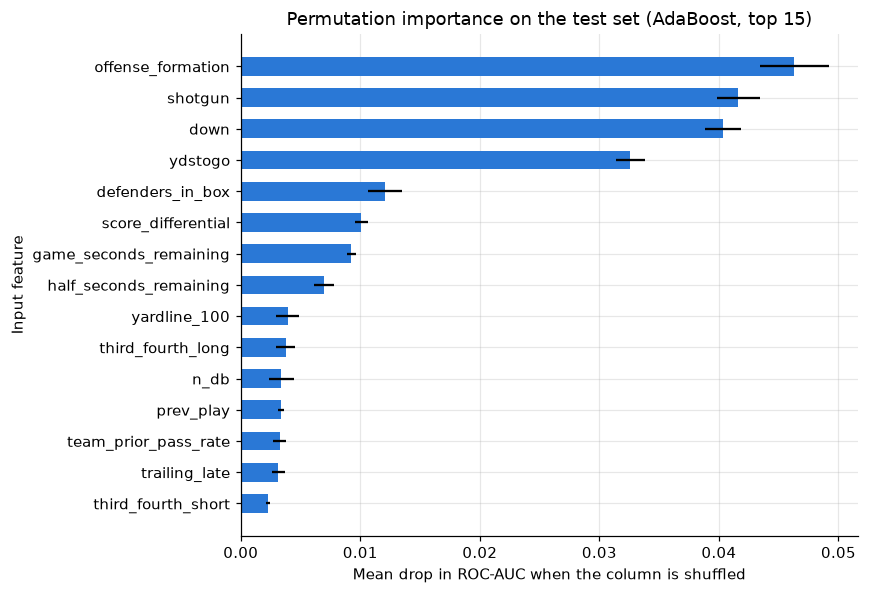

Top 8: {'offense_formation': 0.0463, 'shotgun': 0.0416, 'down': 0.0403, 'ydstogo': 0.0326, 'defenders_in_box': 0.0121, 'score_differential': 0.0101, 'game_seconds_remaining': 0.0093, 'half_seconds_remaining': 0.007}
Features with ~zero importance (< 0.001): ['n_dl', 'no_huddle', 'quarter_seconds_remaining', 'posteam_timeouts_remaining', 'ydstogo_bin', 'offense_personnel', 'defense_personnel', 'defteam_timeouts_remaining', 'n_lb', 'wind', 'goal_to_go', 'is_rain', 'n_wr', 'n_rb', 'n_ol', 'red_zone', 'two_minute', 'is_home', 'is_indoor', 'qtr', 'temp', 'n_te', 'box_minus_blockers', 'drive_play_number']


In [51]:
best_pipe = final_models[best_name]
perm = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"mean AUC drop": perm.importances_mean, "std": perm.importances_std},
                   index=FEATURES).sort_values("mean AUC drop", ascending=False)

top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top["mean AUC drop"], xerr=top["std"], color=SERIES_COLORS[0], height=0.6)
ax.set(title=f"Permutation importance on the test set ({best_name}, top 15)",
       xlabel="Mean drop in ROC-AUC when the column is shuffled", ylabel="Input feature")
plt.tight_layout()
plt.show()
print("Top 8:", imp.head(8)["mean AUC drop"].round(4).to_dict())
print("Features with ~zero importance (< 0.001):", imp.index[imp["mean AUC drop"] < 0.001].tolist())

**Takeaway.** Formation, shotgun, down and distance matter most; weather and most personnel counts add almost nothing.

### 7.5 Error analysis

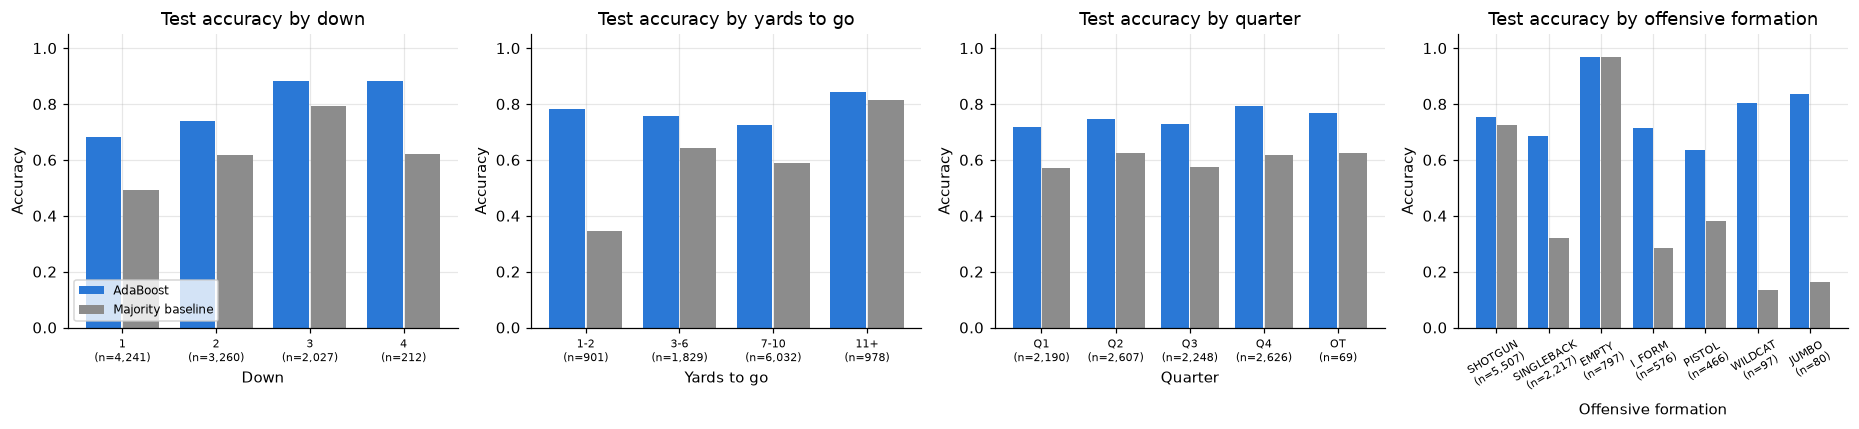

In [52]:
err = test.assign(proba=test_proba[best_name])
err["pred"] = (err["proba"] >= 0.5).astype(int)
err["correct"] = (err["pred"] == err[TARGET]).astype(int)
err["baseline_correct"] = (err[TARGET] == majority_class).astype(int)
err["down_label"] = err["down"].astype(int).astype(str)
err["quarter"] = err["qtr"].astype(int).map({1: "Q1", 2: "Q2", 3: "Q3", 4: "Q4", 5: "OT"})

def by_group(col, order=None):
    g = err.groupby(col, observed=True).agg(plays=("correct", "size"), pass_rate=(TARGET, "mean"),
                                            model_acc=("correct", "mean"), baseline_acc=("baseline_correct", "mean"))
    return g.reindex(order) if order else g

groups_to_plot = [("down_label", "Down", ["1", "2", "3", "4"]),
                  ("ydstogo_bin", "Yards to go", YTG_LABELS),
                  ("quarter", "Quarter", ["Q1", "Q2", "Q3", "Q4", "OT"]),
                  ("offense_formation", "Offensive formation", None)]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (col, label, order) in zip(axes, groups_to_plot):
    g = by_group(col, order)
    if order is None:
        g = g.sort_values("plays", ascending=False)
    xs = np.arange(len(g))
    ax.bar(xs - 0.2, g["model_acc"], width=0.38, color=SERIES_COLORS[0], label=best_name)
    ax.bar(xs + 0.2, g["baseline_acc"], width=0.38, color=NEUTRAL, label="Majority baseline")
    ax.set_xticks(xs, [f"{i}\n(n={n:,})" for i, n in zip(g.index, g["plays"])], fontsize=7,
                  rotation=30 if order is None else 0)
    ax.set(title=f"Test accuracy by {label.lower()}", xlabel=label, ylabel="Accuracy", ylim=(0, 1.05))
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

In [53]:
# situations combining down and distance: where are the most errors in absolute terms?
dd = err.groupby(["down_label", "ydstogo_bin"], observed=True).agg(
    plays=("correct", "size"), pass_rate=(TARGET, "mean"), model_acc=("correct", "mean"),
    errors=("correct", lambda s: int((1 - s).sum())))
dd["share_of_all_errors"] = dd["errors"] / dd["errors"].sum()
print(f"Total test errors: {dd['errors'].sum():,} of {len(err):,} plays")
dd.sort_values("errors", ascending=False).head(8).round(3)

Total test errors: 2,453 of 9,740 plays


plays  pass_rate  model_acc  errors  \
down_label ydstogo_bin                                        
1          7-10          3912      0.490      0.679    1254   
2          7-10          1501      0.707      0.753     370   
           3-6            973      0.497      0.674     317   
3          1-2            433      0.379      0.755     106   
2          11+            470      0.777      0.798      95   
3          3-6            663      0.882      0.894      70   
2          1-2            316      0.329      0.797      64   
1          3-6            133      0.406      0.632      49   

                        share_of_all_errors  
down_label ydstogo_bin                       
1          7-10                       0.511  
2          7-10                       0.151  
           3-6                        0.129  
3          1-2                        0.043  
2          11+                        0.039  
3          3-6                        0.029  
2          1-2                        0.026  
1          3-6                        0.020

In [54]:
# most confident mistakes
show = ["week", "posteam", "defteam", "qtr", "down", "ydstogo", "yardline_100", "score_differential",
        "half_seconds_remaining", "offense_formation", "offense_personnel", "defenders_in_box", "shotgun", TARGET, "proba"]
print(f"{best_name} test scores range from {err['proba'].min():.3f} to {err['proba'].max():.3f}")
wrong = err[err["correct"] == 0].assign(confidence=lambda d: (d["proba"] - 0.5).abs())
wrong.sort_values("confidence", ascending=False)[show].head(8).round(3)

AdaBoost test scores range from 0.276 to 0.813


,week,posteam,defteam,qtr,down,ydstogo,yardline_100,score_differential,half_seconds_remaining,offense_formation,offense_personnel,defenders_in_box,shotgun,is_pass,proba
9435,21,CIN,KC,3.0,3.0,6.0,42.0,-7.0,1560.0,EMPTY,"1 RB, 1 TE, 3 WR",4.0,1.0,0,0.747
579,15,JAX,DAL,2.0,3.0,10.0,65.0,-14.0,6.0,SHOTGUN,"1 RB, 1 TE, 3 WR",3.0,1.0,0,0.743
1493,15,NYG,WAS,1.0,2.0,11.0,65.0,-3.0,943.0,EMPTY,"1 RB, 1 TE, 3 WR",6.0,1.0,0,0.734
9664,22,PHI,KC,2.0,4.0,5.0,44.0,0.0,328.0,EMPTY,"1 RB, 1 TE, 3 WR",5.0,1.0,0,0.733
1650,15,PHI,CHI,2.0,3.0,8.0,22.0,-3.0,48.0,EMPTY,"1 RB, 1 TE, 3 WR",6.0,1.0,0,0.733
9656,22,PHI,KC,2.0,3.0,5.0,51.0,7.0,588.0,EMPTY,"1 RB, 1 TE, 3 WR",5.0,1.0,0,0.730
1258,15,BUF,MIA,2.0,2.0,10.0,82.0,1.0,171.0,EMPTY,"1 RB, 1 TE, 3 WR",5.0,1.0,0,0.727
9524,21,PHI,SF,1.0,2.0,9.0,73.0,7.0,960.0,EMPTY,"1 RB, 1 TE, 3 WR",5.0,1.0,0,0.722


**Takeaway.** 1st-and-10 causes half of all errors. The most confident mistakes are runs from passing formations (draws, QB runs), which pre-snap data can't tell apart.

### 7.6 Conclusions
- All four models beat both baselines and `xpass`; the best reaches 74.8% accuracy (AUC 0.828).
- Inputs mattered more than model choice: merging the participation data was the biggest gain.
- Limits: 1st-and-10 and runs from passing formations are hard to predict, and we only have one season of data.